In [2]:
from google.colab import files

uploaded = files.upload()

Saving popular_movies.csv to popular_movies.csv


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn. metrics import mean_absolute_error, mean_squared_error,r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import spacy
nlp=spacy.load("en_core_web_sm")
from spacy.lang.en.stop_words import STOP_WORDS
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.svm import SVC
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.cluster import BisectingKMeans
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics.pairwise import cosine_similarity

In [4]:
df = pd.read_csv(
    "popular_movies.csv", encoding='latin1'
)
print(df)

                                                  title     budget  \
0                          Final Destination Bloodlines   50000000   
1                                         Lilo & Stitch  100000000   
2                                                 STRAW          0   
3                                           The Amateur   60000000   
4                              How to Train Your Dragon  150000000   
...                                                 ...        ...   
9994                                         The Hunted   55000000   
9995                                     Mujer Perversa          0   
9996                       Sweden: Lessons for America?          0   
9997  JoJo's Bizarre Adventure: Diamond is Unbreakab...          0   
9998                         The Last House on the Left      90000   

                                                 genres original_language  \
0     [{'id': 27, 'name': 'Horror'}, {'id': 9648, 'n...                en   
1    

In [5]:
print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nInformation:")
df.info()


Shape:
(9999, 15)

Columns:
Index(['title', 'budget', 'genres', 'original_language', 'overview',
       'popularity', 'poster_path', 'release_date', 'revenue', 'runtime',
       'spoken_languages', 'vote_average', 'vote_count',
       'production_companies', 'production_countries'],
      dtype='object')

Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   title                 9999 non-null   object 
 1   budget                9999 non-null   int64  
 2   genres                9999 non-null   object 
 3   original_language     9999 non-null   object 
 4   overview              9906 non-null   object 
 5   popularity            9999 non-null   float64
 6   poster_path           9941 non-null   object 
 7   release_date          9978 non-null   object 
 8   revenue               9999 non-null   int64  
 9   runtim

In [6]:
print("\nStatistical Summary:")
print(df.describe())



Statistical Summary:
             budget   popularity       revenue      runtime  vote_average  \
count  9.999000e+03  9999.000000  9.999000e+03  9999.000000   9999.000000   
mean   2.087699e+07     5.816723  6.451290e+07   101.720372      6.226730   
std    4.112951e+07    17.621431  1.617676e+08    30.558504      1.775938   
min    0.000000e+00     0.584800  0.000000e+00     0.000000      0.000000   
25%    0.000000e+00     2.604500  0.000000e+00    90.000000      5.929000   
50%    8.780280e+05     3.473700  2.800000e+06   101.000000      6.600000   
75%    2.500000e+07     5.454600  5.504721e+07   117.000000      7.200000   
max    4.654000e+08  1179.702100  2.923706e+09   417.000000     10.000000   

         vote_count  
count   9999.000000  
mean    1763.272527  
std     3297.615643  
min        0.000000  
25%       51.000000  
50%      529.000000  
75%     1937.500000  
max    37567.000000  


In [7]:
print("\nNull Values:")
print(df.isnull().sum())



Null Values:
title                    0
budget                   0
genres                   0
original_language        0
overview                93
popularity               0
poster_path             58
release_date            21
revenue                  0
runtime                  0
spoken_languages         0
vote_average             0
vote_count               0
production_companies     0
production_countries     0
dtype: int64


In [8]:
num_cols = df.select_dtypes(
    include=np.number
).columns

for col in num_cols:
    df[col] = df[col].fillna(
        df[col].median()
    )


cat_cols = df.select_dtypes(
    include="object"
).columns

for col in cat_cols:
    df[col] = df[col].fillna(
        df[col].mode()[0]
    )

df = df.dropna()

print("\nNull Values After Handling:")
print(df.isnull().sum())


Null Values After Handling:
title                   0
budget                  0
genres                  0
original_language       0
overview                0
popularity              0
poster_path             0
release_date            0
revenue                 0
runtime                 0
spoken_languages        0
vote_average            0
vote_count              0
production_companies    0
production_countries    0
dtype: int64


In [9]:
print("\nDuplicate Rows:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates After Removal:")
print(df.duplicated().sum())


Duplicate Rows:
592
Duplicates After Removal:
0


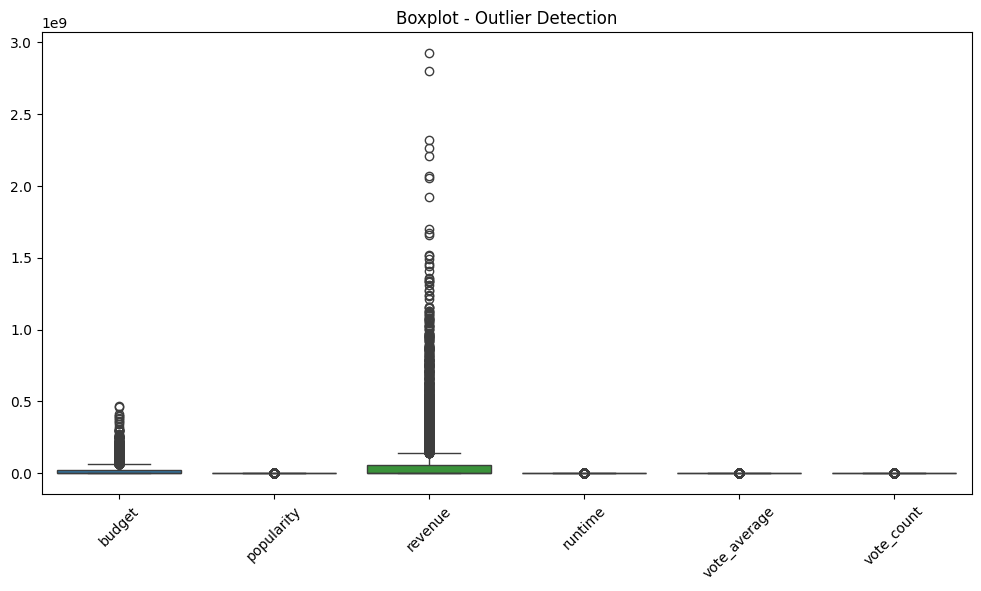

In [10]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df
)
plt.title("Boxplot - Outlier Detection")
plt.xticks(rotation=45)
plt.show()

In [11]:
cols = df.select_dtypes(include=np.number).columns

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df = df[
        (df[col] >= lower_limit) &
        (df[col] <= upper_limit)
    ]
print(df.shape)

(5196, 15)


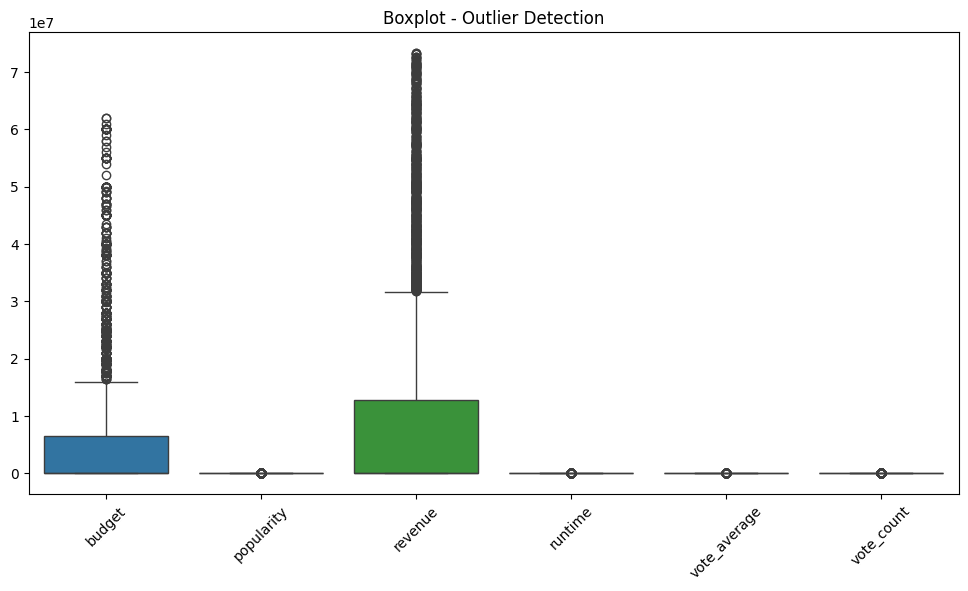

In [12]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df
)
plt.title("Boxplot - Outlier Detection")
plt.xticks(rotation=45)
plt.show()

In [1]:
plt.figure(figsize=(10,6))

df.isnull().sum().sort_values(ascending=False).plot(
    kind='bar'
)

plt.title("Missing Values in Movie Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)

plt.show()

NameError: name 'plt' is not defined

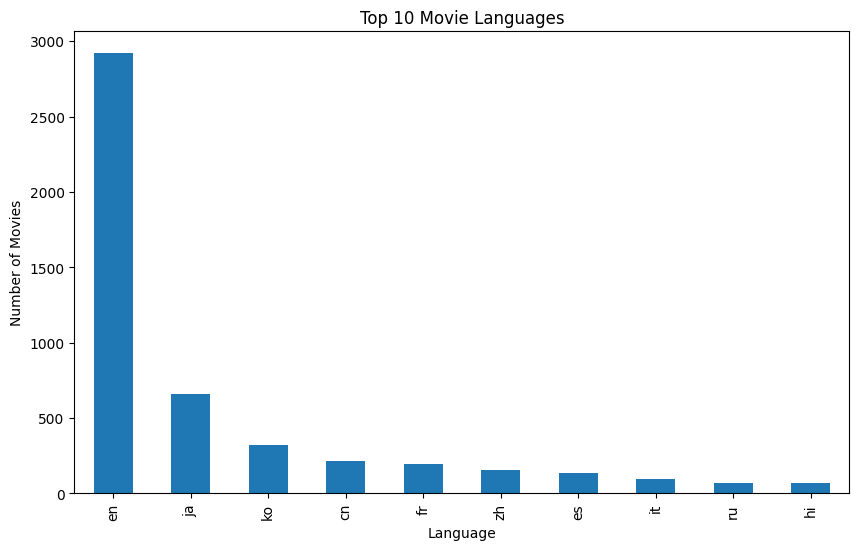

In [13]:
language_count = df['original_language'].value_counts().head(10)

plt.figure(figsize=(10,6))

language_count.plot(kind='bar')

plt.title("Top 10 Movie Languages")
plt.xlabel("Language")
plt.ylabel("Number of Movies")

plt.show()

In [14]:
def extract_genres(x):
    try:
        data = ast.literal_eval(x)
        return [i['name'] for i in data]
    except:
        return []

df['genre_list'] = df['genres'].apply(extract_genres)

print(df[['title', 'genre_list']].head())

                                  title genre_list
664                Oxen Split Torturing         []
887  Guinea Pig: Mermaid in the Manhole         []
921                        Founders Day         []
932                          Quarantine         []
943           The Pig & I: A Love Story         []


In [15]:
genre_count = {}

for genres in df['genre_list']:
    for genre in genres:
        genre_count[genre] = genre_count.get(genre, 0) + 1

genre_df = pd.DataFrame(
    genre_count.items(),
    columns=['Genre', 'Count']
).sort_values(
    'Count',
    ascending=False
)

print(genre_df)

Empty DataFrame
Columns: [Genre, Count]
Index: []


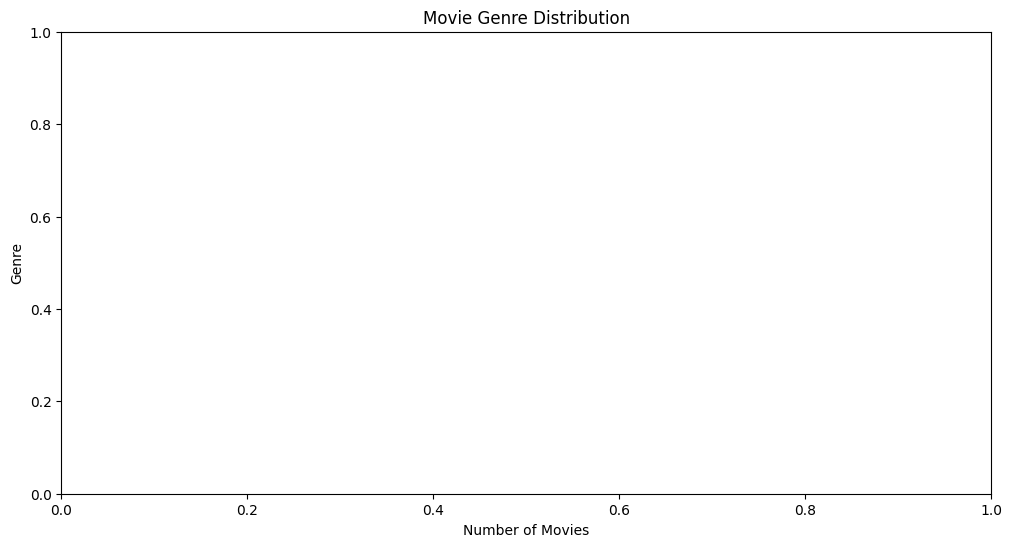

In [16]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=genre_df,
    x='Count',
    y='Genre'
)

plt.title("Movie Genre Distribution")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.show()

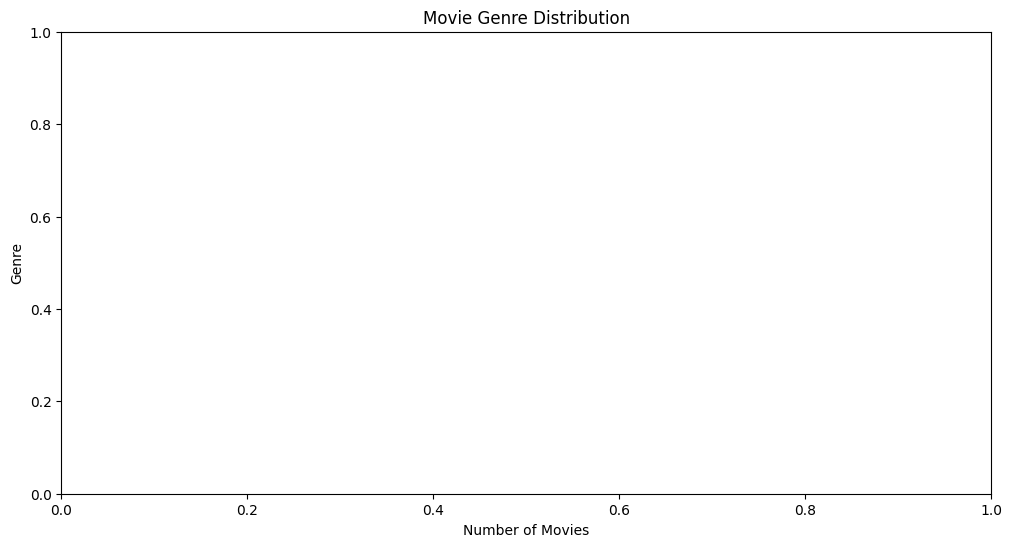

In [17]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=genre_df,
    x='Count',
    y='Genre'
)

plt.title("Movie Genre Distribution")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.show()

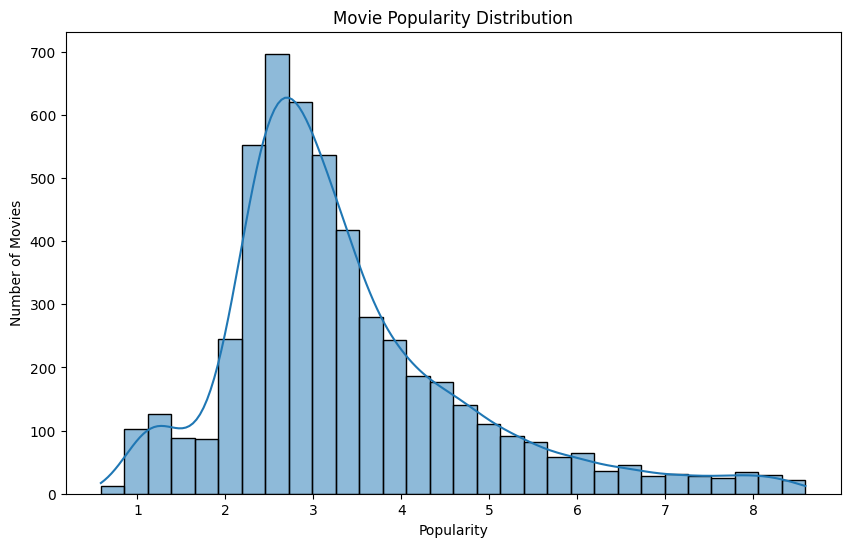

In [18]:
plt.figure(figsize=(10,6))

sns.histplot(
    df['popularity'].dropna(),
    bins=30,
    kde=True
)

plt.title("Movie Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Number of Movies")

plt.show()

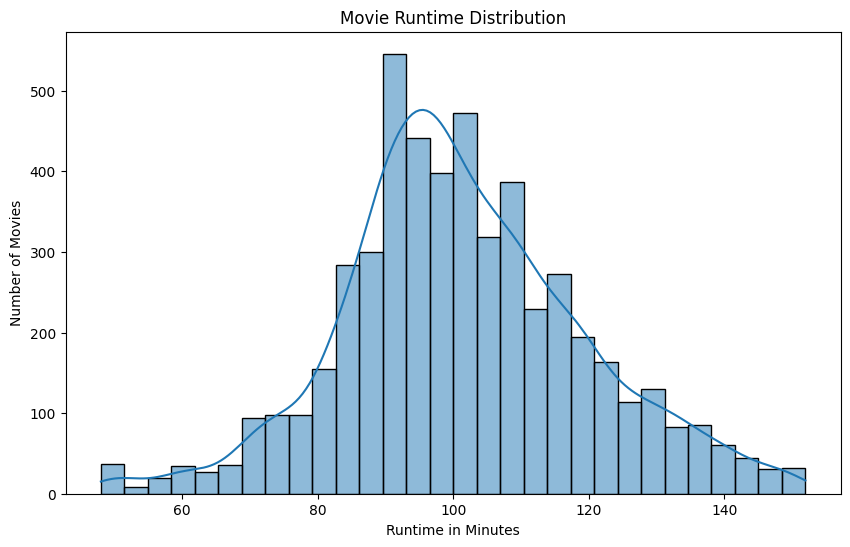

In [19]:
plt.figure(figsize=(10,6))

sns.histplot(
    df['runtime'].dropna(),
    bins=30,
    kde=True
)

plt.title("Movie Runtime Distribution")
plt.xlabel("Runtime in Minutes")
plt.ylabel("Number of Movies")

plt.show()

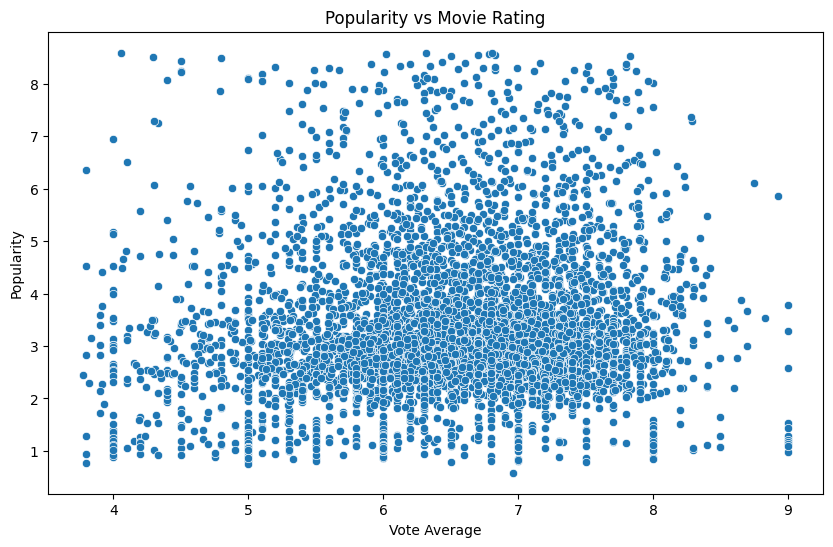

In [20]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='vote_average',
    y='popularity'
)

plt.title("Popularity vs Movie Rating")
plt.xlabel("Vote Average")
plt.ylabel("Popularity")

plt.show()

In [21]:
top_rated = df[df['vote_count'] >= 100] \
    .sort_values('vote_average', ascending=False) \
    .head(10)

print(
    top_rated[
        ['title', 'vote_average', 'vote_count']
    ]
)

                                     title  vote_average  vote_count
4808            Selena Gomez: My Mind & Me         8.558         474
9271  Teasing Master Takagi-san: The Movie         8.500         130
3461                              Harakiri         8.423        1088
7970                     Gabriel's Inferno         8.411        2423
5992           Gabriel's Inferno: Part III         8.400        1058
7012                          A Dog's Will         8.400        1165
3098                                  Hope         8.396         784
4044           La Leyenda de los Chaneques         8.373         236
3600                               Radical         8.360         457
2964                          High and Low         8.348         986


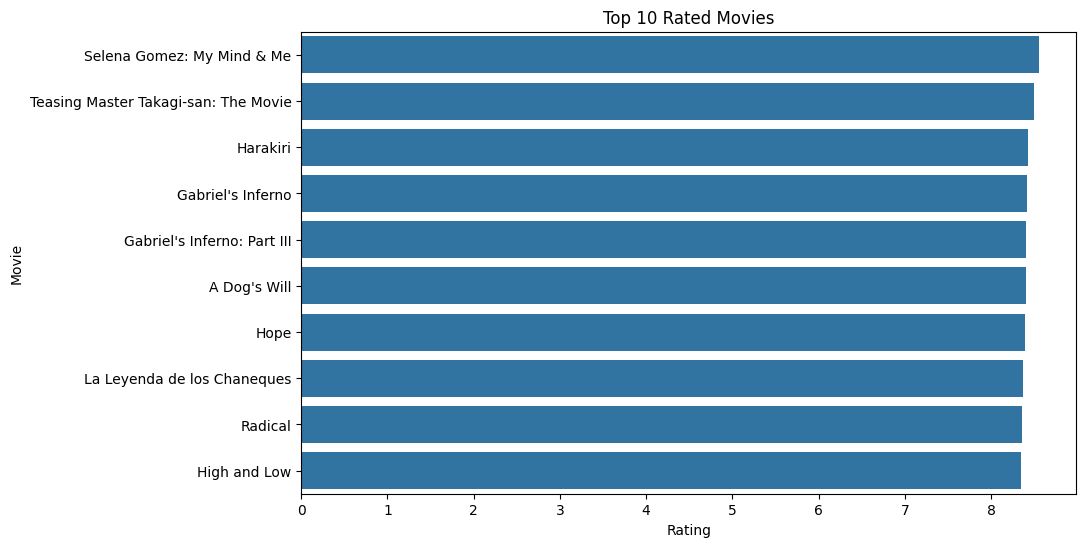

In [22]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_rated,
    x='vote_average',
    y='title'
)

plt.title("Top 10 Rated Movies")
plt.xlabel("Rating")
plt.ylabel("Movie")

plt.show()

In [23]:
df['genres_text'] = df['genre_list'].apply(
    lambda x: ' '.join(x)
)

In [24]:
df['overview'] = df['overview'].fillna('')
df['original_language'] = df['original_language'].fillna('')
df['genres_text'] = df['genres_text'].fillna('')

In [25]:
df['content'] = (
    df['genres_text'] + ' ' +
    df['overview'] + ' ' +
    df['original_language']
)

In [26]:
print(df[['title', 'content']].head())

                                  title  \
664                Oxen Split Torturing   
887  Guinea Pig: Mermaid in the Manhole   
921                        Founders Day   
932                          Quarantine   
943           The Pig & I: A Love Story   

                                               content  
664   Two short stories set in Edo during the Shogu...  
887   An artist dealing with the grief of his wife ...  
921   A small town is shaken by a series of ominous...  
932   Describing herself as a "trouble magnet," Zey...  
943   Alone on a farm, a man spends his days tendin...  


In [27]:
tfidf = TfidfVectorizer(
    stop_words='english'
)

tfidf_matrix = tfidf.fit_transform(
    df['content']
)

print("TF-IDF Shape:", tfidf_matrix.shape)

TF-IDF Shape: (5196, 20818)


In [28]:
cosine_sim = cosine_similarity(
    tfidf_matrix
)

print("Similarity Matrix:", cosine_sim.shape)

Similarity Matrix: (5196, 5196)


In [29]:
indices = pd.Series(
    df.index,
    index=df['title']
).drop_duplicates()

In [30]:
def recommend_movies(movie_name, n=10):

    if movie_name not in indices:
        print("Movie not found")
        return

    idx = indices[movie_name]

    scores = list(
        enumerate(cosine_sim[idx])
    )

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    scores = scores[1:n+1]

    movie_indices = [
        i[0] for i in scores
    ]

    result = df.iloc[movie_indices][
        [
            'title',
            'genres_text',
            'vote_average',
            'popularity'
        ]
    ].copy()

    result['similarity_score'] = [
        round(i[1], 3)
        for i in scores
    ]

    return result

In [31]:
recommend_movies(
    "Chaos: The Manson Murders",
    20
)

,title,genres_text,vote_average,popularity,similarity_score
3979,Alone In The Night,,6.125,3.5518,0.132
1141,Baby Face,,7.254,6.5071,0.112
7042,Sister Death,,5.960,2.9164,0.111
8669,Murderous Minds: Fred & Rose West,,7.500,0.8607,0.111
3265,The Magic of Ordinary Days,,7.333,3.7055,0.109
8067,Hold Your Breath,,5.932,2.7494,0.097
2720,My Cousin the Sexologist,,6.779,4.9945,0.095
1727,Sex,,6.630,6.3512,0.094
979,The 33D Invader,,5.600,8.2917,0.093
6939,Cursed,,6.306,2.5381,0.085


In [32]:
recommend_movies(
    "Barbie & Teresa: Recipe for Friendship",
    10
)

,title,genres_text,vote_average,popularity,similarity_score
4122,On the Waterfront,,7.900,5.0596,0.162
3119,Red Right Hand,,6.677,4.6585,0.159
1229,El Candidato Honesto,,6.654,5.4242,0.151
1393,"No manches, Frida",,7.684,6.4114,0.149
4142,The Real McCoy,,5.700,2.2684,0.136
6761,The Out-Laws,,6.019,3.0572,0.131
4054,Nineteen Eighty-Four,,6.808,4.0937,0.127
9578,The Long Riders,,6.670,2.3561,0.119
1824,Blue Lagoon: The Awakening,,6.440,7.8901,0.118
4821,Qalb,,5.000,3.5243,0.115
